# EDA - Exploratory Data Analysis

In [54]:
import numpy as mp
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Extract data to analyze
Filter by students who studied in Hungary

In [11]:
df = pd.read_csv("./datasets/forms-answers-cleaned-hungary.csv")

In [12]:
display(df.head(5))

,0,1,3,4,5,6,7,8,9,10,...,92,93,94,95,96,97,98,99,100,101
0,2026-04-19 19:33:39+00:00,Yes,20-24,Woman,Lebanese,NaN,Hungary,5+,Diagnosed neurodivergent (you have received a ...,ASD – Autism Spectrum Disorder;OCD – Obsessive...,...,7,7,7,7,7,7,5,5,Teach differently and interact more rather tha...,NaN
1,2026-04-19 20:01:35+00:00,Yes,30-34,Woman,Japan America,Asian White,Hungary,5+,Neurotypical,NaN,...,2,3,7,7,7,7,3,5,allowing different learning tools for students...,ITS HARD but worth it - self growth
2,2026-04-21 08:32:29+00:00,Yes,25-29,Woman,Tunisian,Afro-Arab,Hungary,4,Diagnosed neurodivergent (you have received a ...,Anxiety Disorder;Depression Disorder;PTSD – Po...,...,2,4,6,7,7,4,4,5,"Extra time should be more easily accessible, I...",NaN
3,2026-04-21 08:32:43+00:00,Yes,20-24,Woman,Lebanese,Arab,Hungary,Graduated,Self identified neurodivergent (no formal diag...,Anxiety Disorder;Not sure,...,5,7,7,7,7,7,2,5,Provide different tools for teaching and imple...,The language barrier of being in Hungary affec...
4,2026-04-25 07:26:10+00:00,Yes,20-24,Woman,German,NaN,Hungary,2,Neurotypical,Depression Disorder,...,7,6,6,6,7,7,3,5,NaN,NaN


In [ ]:
display(df.shape)
display(df.describe())

(79, 101)

,16,17,23,24,25,26,27,28,41,42,...,90,91,92,93,94,95,96,97,98,99
count,79.000000,77.000000,79.000000,79.000000,79.000000,79.000000,75.000000,45.000000,79.000000,79.000000,...,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000
mean,3.025316,2.727273,2.405063,2.556962,3.848101,4.329114,4.533333,3.088889,3.278481,2.810127,...,5.126582,4.367089,4.265823,5.037975,5.354430,5.417722,5.518987,5.443038,2.911392,4.506329
std,1.109108,1.059250,0.940799,0.943899,0.907075,0.901872,0.759326,1.183643,1.131560,1.241132,...,1.771332,1.889086,2.061297,2.009229,1.561048,1.524228,1.663028,1.654418,1.052346,0.845401
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,2.000000,2.000000,2.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,...,4.000000,3.000000,2.500000,4.000000,4.000000,4.000000,4.000000,4.000000,2.000000,4.000000
50%,3.000000,3.000000,2.000000,3.000000,4.000000,5.000000,5.000000,3.000000,3.000000,2.000000,...,5.000000,4.000000,5.000000,5.000000,5.000000,6.000000,6.000000,6.000000,3.000000,5.000000
75%,4.000000,3.000000,3.000000,3.000000,4.500000,5.000000,5.000000,4.000000,4.000000,4.000000,...,7.000000,6.000000,6.000000,7.000000,7.000000,7.000000,7.000000,7.000000,4.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,5.000000,5.000000


# How common are mental health issues in respondents
How many have experienced anxiety or depression in the past two weeks before the survey.

## Neurodivergent vs not neurodivergent students

This bar chart shows how many students in the Hungary sample (n = 79) identify as neurodivergent compared with those who do not.

Grouping is based on the question *"How do you identify yourself?"* (column 9), which allowed more than one answer:
- **Neurodivergent**: the student selected *Diagnosed neurodivergent* and/or *Self identified neurodivergent*, even if they also ticked another option (42 students, 53%).
- **Not neurodivergent**: the student selected only *Neurotypical* and/or *I haven't thought much of it* (37 students, 47%).

The two groups are close in size, which makes later comparisons between them reasonably balanced.

nd_group
Neurodivergent        42
Not neurodivergent    37
Name: count, dtype: int64

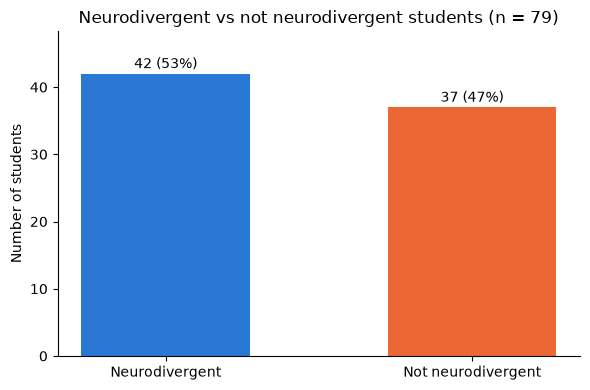

In [55]:
ND_COLOR = "#2a78d6"
NON_ND_COLOR = "#eb6834"

# Column 9 is multi-select: anyone who ticked a "neurodivergent" option (diagnosed or self-identified) counts as ND
df["neurodivergent"] = df["9"].str.contains("neurodivergent", case=False, na=False)
df["nd_group"] = df["neurodivergent"].map({True: "Neurodivergent", False: "Not neurodivergent"})

nd_counts = df["nd_group"].value_counts().reindex(["Neurodivergent", "Not neurodivergent"])
display(nd_counts)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(nd_counts.index, nd_counts.values, color=[ND_COLOR, NON_ND_COLOR], width=0.55)
for bar, n in zip(bars, nd_counts.values):
    ax.annotate(f"{n} ({n / nd_counts.sum():.0%})", (bar.get_x() + bar.get_width() / 2, n),
                xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_ylabel("Number of students")
ax.set_title(f"Neurodivergent vs not neurodivergent students (n = {nd_counts.sum()})")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, nd_counts.max() * 1.15)
plt.tight_layout()
plt.show()

## Diagnosed vs self-identified neurodivergent students

These charts look only at the **42 neurodivergent students** from the previous chart.

**Left: diagnosed vs self-identified** (column 9)
- **Diagnosed**: the student ticked *Diagnosed neurodivergent*. This includes 4 students who also ticked *Self identified*, because they do have a medical diagnosis.
- **Self-identified only**: the student ticked *Self identified neurodivergent (no formal diagnosis)* and not *Diagnosed*.

**Right: conditions that apply to them** (column 10, more than one answer allowed)
- Each bar is the **% of students in that group** who ticked the condition, so the two groups can be compared even though they are different sizes. The number of students is written next to each bar.
- Because students could tick several conditions, the percentages add up to more than 100%.


,students
diagnosis,
Diagnosed,25
Self-identified only,17


students                       \
diagnosis                            Diagnosed Self-identified only   
ADHD                                        18                    9   
Anxiety Disorder                            11                    9   
ASD                                          8                    5   
Depression Disorder                          8                    2   
OCD                                          1                    3   
APD                                          2                    1   
Dyslexia                                     3                    0   
PTSD                                         1                    2   
Bipolar Disorder                             2                    0   
Sensory Processing Differences (SPD)         2                    0   
BPD                                          1                    0   
Dyspraxia / DCD                              1                    0   
Not sure                                     0                    5   

                                     % of group                       
diagnosis                             Diagnosed Self-identified only  
ADHD                                       72.0                 53.0  
Anxiety Disorder                           44.0                 53.0  
ASD                                        32.0                 29.0  
Depression Disorder                        32.0                 12.0  
OCD                                         4.0                 18.0  
APD                                         8.0                  6.0  
Dyslexia                                   12.0                  0.0  
PTSD                                        4.0                 12.0  
Bipolar Disorder                            8.0                  0.0  
Sensory Processing Differences (SPD)        8.0                  0.0  
BPD                                         4.0                  0.0  
Dyspraxia / DCD                             4.0                  0.0  
Not sure                                    0.0                 29.0

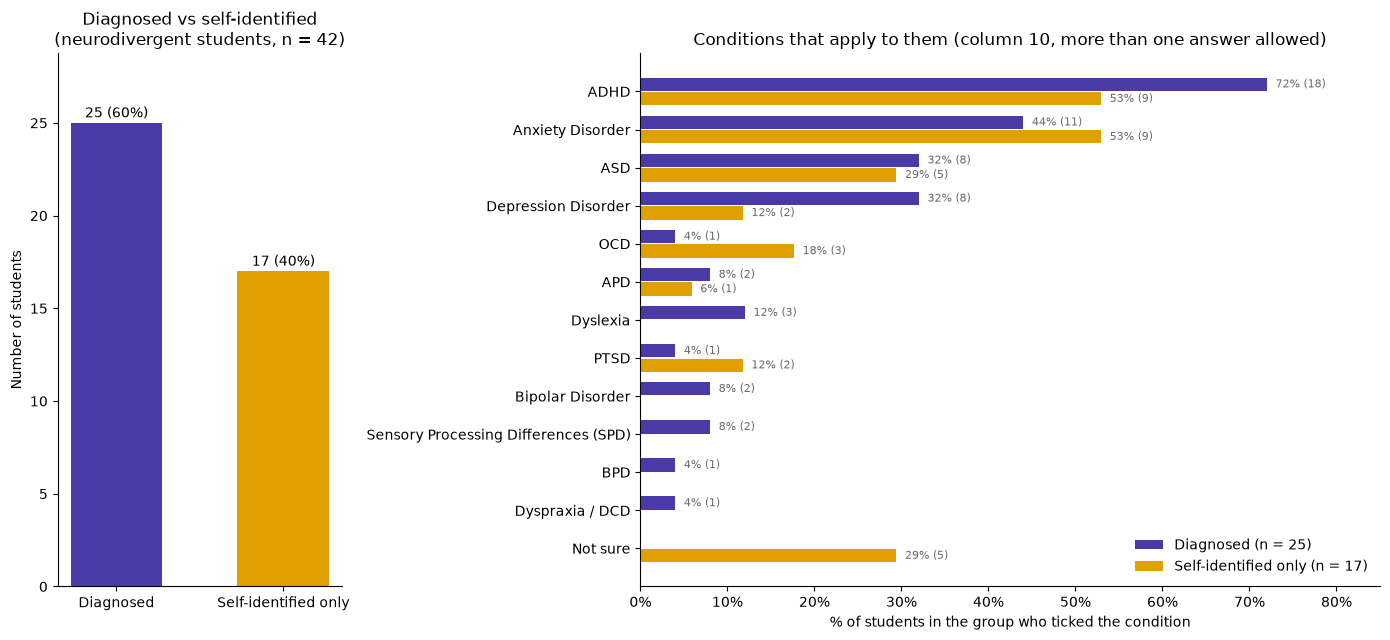

In [71]:
import numpy as np

DIAG_COLOR = "#4a3aa7"
SELF_COLOR = "#e0a100"
DIAG_ORDER = ["Diagnosed", "Self-identified only"]

nd = df[df["neurodivergent"]].copy()
# Anyone who ticked "Diagnosed" counts as diagnosed, even if they also ticked "Self identified"
nd["diagnosis"] = nd["9"].str.contains("Diagnosed", na=False).map({True: "Diagnosed", False: "Self-identified only"})
diag_counts = nd["diagnosis"].value_counts().reindex(DIAG_ORDER)
group_sizes = diag_counts.to_dict()

# Column 10 is multi-select: one True/False column per condition
conditions = nd["10"].str.get_dummies(sep=";")
conditions.columns = conditions.columns.str.split(" – ").str[0]  # "ADHD – Attention Deficit..." -> "ADHD"
cond_counts = conditions.groupby(nd["diagnosis"]).sum().T.reindex(columns=DIAG_ORDER)
cond_pct = cond_counts / diag_counts
# Most common conditions first; "Not sure" / "None" are kept at the bottom
other = [c for c in ["Not sure", "None"] if c in cond_counts.index]
order = cond_counts.drop(other).sum(axis=1).sort_values(ascending=False).index.tolist() + other
cond_counts, cond_pct = cond_counts.loc[order], cond_pct.loc[order]

display(diag_counts.to_frame("students"))
display(pd.concat({"students": cond_counts, "% of group": (cond_pct * 100).round(0)}, axis=1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 2.6]})

# Left: diagnosed vs self-identified
bars = ax1.bar(DIAG_ORDER, diag_counts.values, color=[DIAG_COLOR, SELF_COLOR], width=0.55)
for bar, n in zip(bars, diag_counts.values):
    ax1.annotate(f"{n} ({n / diag_counts.sum():.0%})", (bar.get_x() + bar.get_width() / 2, n),
                 xytext=(0, 4), textcoords="offset points", ha="center")
ax1.set_ylabel("Number of students")
ax1.set_ylim(0, diag_counts.max() * 1.15)
ax1.set_title(f"Diagnosed vs self-identified\n(neurodivergent students, n = {diag_counts.sum()})")
ax1.spines[["top", "right"]].set_visible(False)

# Right: % of each group with each condition
y = np.arange(len(order))
h = 0.38
for offset, group, color in [(-h / 2, "Diagnosed", DIAG_COLOR), (h / 2, "Self-identified only", SELF_COLOR)]:
    ax2.barh(y + offset, cond_pct[group], height=h - 0.03, color=color,
             label=f"{group} (n = {group_sizes[group]})")
    for yi, pct, n in zip(y + offset, cond_pct[group], cond_counts[group]):
        if n > 0:
            ax2.text(pct + 0.01, yi, f"{pct:.0%} ({n})", va="center", fontsize=8, color="dimgrey")
ax2.set_yticks(y, order)
ax2.invert_yaxis()
ax2.set_xlim(0, 0.85)
ax2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax2.set_xlabel("% of students in the group who ticked the condition")
ax2.set_title("Conditions that apply to them (column 10, more than one answer allowed)")
ax2.legend(frameon=False, loc="lower right")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


### When students were diagnosed, by condition

This looks at the **36 students who say they have received a diagnosis** (column 11: *"When did you receive your diagnosis, if any?"*), split by **when** they got it: **before** or **during** vet school.

- This group is not exactly the same as the 25 "diagnosed neurodivergent" students above. Column 11 asks about *any* diagnosis, so it also includes 9 students who did not identify as neurodivergent (most likely diagnosed with anxiety or depression) and 2 self-identified students who answered *During vet school*.
- **Left:** how many students were diagnosed before vs during vet school.
- **Right:** for each condition in column 10, the **% of students in each timing group** who ticked it, with the number of students next to each bar. Percentages add up to more than 100% because students could tick several conditions.
- *Not sure* answers are left out, since they are not a condition. The percentages are still out of everyone in the timing group.
- **Limit:** the survey asks *when* the diagnosis was received, but not *which* condition it was for. A student diagnosed during vet school with ADHD may also tick anxiety without an anxiety diagnosis, so this chart shows which conditions are common in each group, not the exact timing of each diagnosis.


11,Before vet school,During vet school
9,,
Diagnosed neurodivergent (you have received a medical diagnosis),11,10
Diagnosed neurodivergent (you have received a medical diagnosis);Self identified neurodivergent (no formal diagnosis),1,3
I haven't thought much of it.,4,0
Neurotypical,3,1
Neurotypical;I haven't thought much of it.,0,1
Self identified neurodivergent (no formal diagnosis),0,2


,students
11,
Before vet school,19
During vet school,17


students                    \
11                                   Before vet school During vet school   
ADHD                                                12                 8   
Anxiety Disorder                                     7                 9   
Depression Disorder                                 10                 5   
ASD                                                  3                 5   
Dyslexia                                             4                 1   
APD                                                  1                 1   
Bipolar Disorder                                     0                 2   
PTSD                                                 1                 1   
Sensory Processing Differences (SPD)                 1                 1   
BPD                                                  1                 0   
Dyspraxia / DCD                                      1                 0   
OCD                                                  0                 1   

                                            % of group                    
11                                   Before vet school During vet school  
ADHD                                              63.0              47.0  
Anxiety Disorder                                  37.0              53.0  
Depression Disorder                               53.0              29.0  
ASD                                               16.0              29.0  
Dyslexia                                          21.0               6.0  
APD                                                5.0               6.0  
Bipolar Disorder                                   0.0              12.0  
PTSD                                               5.0               6.0  
Sensory Processing Differences (SPD)               5.0               6.0  
BPD                                                5.0               0.0  
Dyspraxia / DCD                                    5.0               0.0  
OCD                                                0.0               6.0

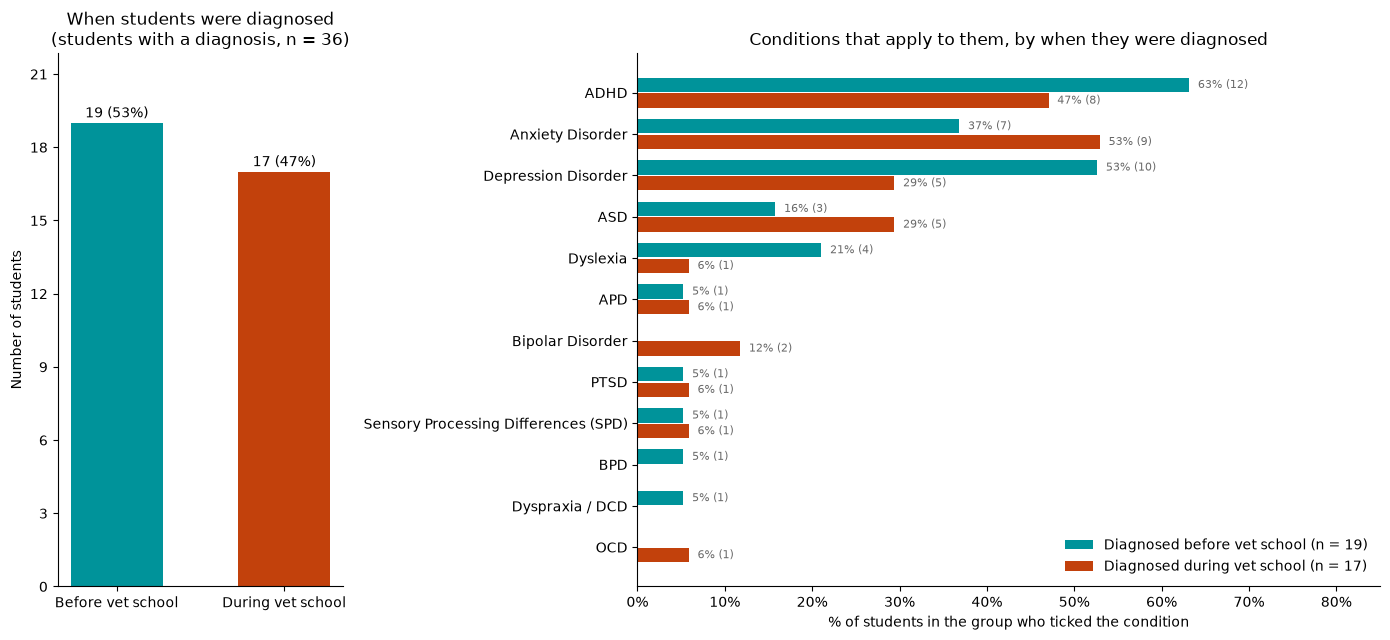

In [74]:
BEFORE_COLOR = "#00939a"
DURING_COLOR = "#c2410c"
TIMING_ORDER = ["Before vet school", "During vet school"]

diagnosed = df[df["11"].isin(TIMING_ORDER)].copy()
timing_counts = diagnosed["11"].value_counts().reindex(TIMING_ORDER)
display(pd.crosstab(diagnosed["9"], diagnosed["11"]))  # who is in each timing group

# Column 10 is multi-select: one True/False column per condition
timing_conditions = diagnosed["10"].str.get_dummies(sep=";")
timing_conditions.columns = timing_conditions.columns.str.split(" – ").str[0]
timing_counts_cond = timing_conditions.groupby(diagnosed["11"]).sum().T.reindex(columns=TIMING_ORDER)
timing_pct = timing_counts_cond / timing_counts
# "Not sure" / "None" are not conditions, so they are left out; most common conditions first
timing_counts_cond = timing_counts_cond.drop(["Not sure", "None"], errors="ignore")
timing_pct = timing_pct.drop(["Not sure", "None"], errors="ignore")
order = timing_counts_cond.sum(axis=1).sort_values(ascending=False).index.tolist()
timing_counts_cond, timing_pct = timing_counts_cond.loc[order], timing_pct.loc[order]

display(timing_counts.to_frame("students"))
display(pd.concat({"students": timing_counts_cond, "% of group": (timing_pct * 100).round(0)}, axis=1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 2.6]})

# Left: diagnosed before vs during vet school
bars = ax1.bar(TIMING_ORDER, timing_counts.values, color=[BEFORE_COLOR, DURING_COLOR], width=0.55)
for bar, n in zip(bars, timing_counts.values):
    ax1.annotate(f"{n} ({n / timing_counts.sum():.0%})", (bar.get_x() + bar.get_width() / 2, n),
                 xytext=(0, 4), textcoords="offset points", ha="center")
ax1.set_ylabel("Number of students")
ax1.set_ylim(0, timing_counts.max() * 1.15)
ax1.yaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=True))
ax1.set_title(f"When students were diagnosed\n(students with a diagnosis, n = {timing_counts.sum()})")
ax1.spines[["top", "right"]].set_visible(False)

# Right: % of each timing group with each condition
y = np.arange(len(order))
h = 0.38
for offset, group, color in [(-h / 2, "Before vet school", BEFORE_COLOR), (h / 2, "During vet school", DURING_COLOR)]:
    ax2.barh(y + offset, timing_pct[group], height=h - 0.03, color=color,
             label=f"Diagnosed {group.lower()} (n = {timing_counts[group]})")
    for yi, pct, n in zip(y + offset, timing_pct[group], timing_counts_cond[group]):
        if n > 0:
            ax2.text(pct + 0.01, yi, f"{pct:.0%} ({n})", va="center", fontsize=8, color="dimgrey")
ax2.set_yticks(y, order)
ax2.invert_yaxis()
ax2.set_xlim(0, 0.85)
ax2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax2.set_xlabel("% of students in the group who ticked the condition")
ax2.set_title("Conditions that apply to them, by when they were diagnosed")
ax2.legend(frameon=False, loc="lower right")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


## Anxiety and depression screening

These two line graphs give a first look at how many students in the sample screen positive for **depression** and for **anxiety**. Each graph is read separately. A student can have one condition, both, or neither.

- **Depression (left)** uses the PHQ-9: 9 items (columns 70–78), each scored 0–3, so totals run from 0 to 27.
- **Anxiety (right)** uses the GAD-7: 7 items (columns 79–85), each scored 0–3, so totals run from 0 to 21.
- The **line** shows how many students got each total score.
- The **shaded area** covers scores of 10 or more, the standard cut-off for at least *moderate* symptoms on both questionnaires. The count of students in that area is written at the top of each graph.
- The tables printed above the plot break each score into its standard severity bands.

Two students skipped the whole PHQ-9, so the depression graph shows 77 students and the anxiety graph shows 79.

Depression: n = 77, mean = 14.7, median = 14, score ≥ 10: 59 (77%)


,students
phq9_total,
Minimal (0-4),2
Mild (5-9),16
Moderate (10-14),23
Moderately severe (15-19),17
Severe (20-27),19


Anxiety (GAD-7): n = 79, mean = 12.3, median = 13, score ≥ 10: 58 (73%)


,students
gad7_total,
Minimal (0-4),9
Mild (5-9),12
Moderate (10-14),28
Severe (15-21),30


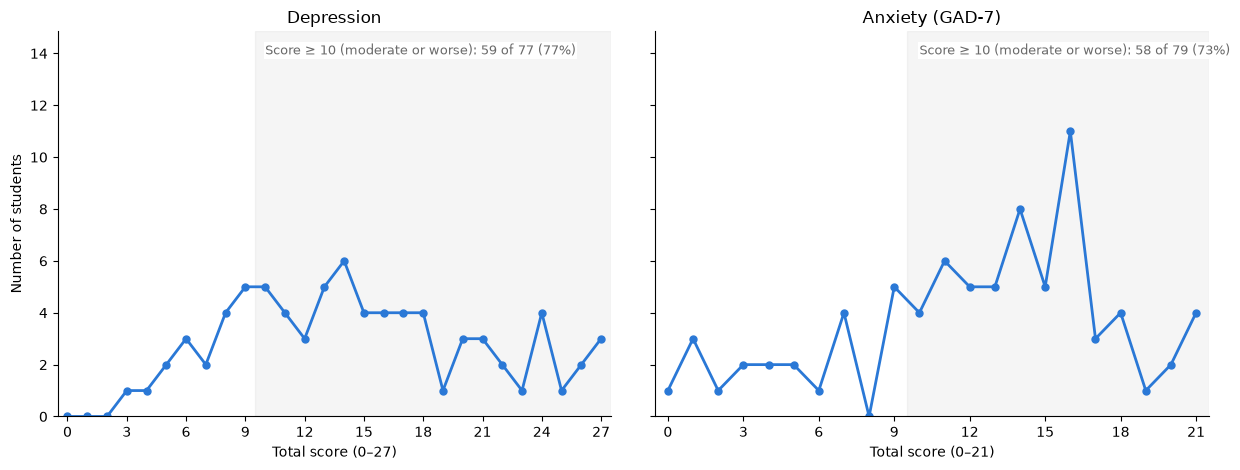

In [73]:
PHQ9_COLS = [str(c) for c in range(70, 79)]  # depression items, each 0-3
GAD7_COLS = [str(c) for c in range(79, 86)]  # anxiety items, each 0-3

def screening_total(items):
    # Prorate when at most one item is missing; otherwise leave the score empty
    answered = items.notna().sum(axis=1)
    total = items.mean(axis=1) * items.shape[1]
    return total.where(answered >= items.shape[1] - 1).round()

df["phq9_total"] = screening_total(df[PHQ9_COLS])
df["gad7_total"] = screening_total(df[GAD7_COLS])

PHQ9_BANDS = ([-1, 4, 9, 14, 19, 27], ["Minimal (0-4)", "Mild (5-9)", "Moderate (10-14)", "Moderately severe (15-19)", "Severe (20-27)"])
GAD7_BANDS = ([-1, 4, 9, 14, 21], ["Minimal (0-4)", "Mild (5-9)", "Moderate (10-14)", "Severe (15-21)"])

screenings = [
    ("Depression", "phq9_total", 27, PHQ9_BANDS),
    ("Anxiety (GAD-7)", "gad7_total", 21, GAD7_BANDS),
]

# Shared y-axis so the two line heights can be compared directly
y_max = max(df[col].value_counts().max() for _, col, _, _ in screenings) * 1.35

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (name, col, max_score, (bins, labels)) in zip(axes, screenings):
    scores = df[col].dropna()
    n = len(scores)
    positive = (scores >= 10).sum()

    print(f"{name}: n = {n}, mean = {scores.mean():.1f}, median = {scores.median():.0f}, "
          f"score ≥ 10: {positive} ({positive / n:.0%})")
    display(pd.cut(scores, bins=bins, labels=labels).value_counts().sort_index().to_frame("students"))

    # Number of students at every possible score, including scores nobody got
    counts = scores.value_counts().reindex(range(max_score + 1), fill_value=0)
    ax.axvspan(9.5, max_score + 0.5, color="grey", alpha=0.08)
    ax.text(10, y_max * 0.94, f"Score ≥ 10 (moderate or worse): {positive} of {n} ({positive / n:.0%})",
            fontsize=9, color="dimgrey", bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.plot(counts.index, counts.values, color=ND_COLOR, linewidth=2, marker="o", markersize=5)

    ax.set_title(name)
    ax.set_xlabel(f"Total score (0–{max_score})")
    ax.set_xticks(range(0, max_score + 1, 3))
    ax.set_xlim(-0.5, max_score + 0.5)
    ax.set_ylim(0, y_max)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Number of students")
plt.tight_layout()
plt.show()

## High expectations and workload in veterinary school environments


### Academic overwhelm score

This bar chart shows how overwhelmed students feel by the demands of veterinary school.

**How the score was calculated**
- Two questions were combined, both answered from 1 (strongly disagree) to 5 (strongly agree):
  - Column 26: *"I feel overwhelmed by the volume of academic **expectations** in my program."*
  - Column 27: *"I feel overwhelmed by the volume of academic **workload** in my program."*
- The **overwhelm score is the average of the two answers**. For example, a student who answered 4 and 5 gets 4.5.
- 4 students skipped column 27, so their score is just their column 26 answer.
- A score of **4 or more** (shaded area) means the student agrees that they feel overwhelmed. These students form the **high overwhelm** group in the next charts.

**Why the two questions can be combined**

The two answers are strongly related: **Spearman correlation ρ = 0.73** (p < 0.001). The correlation goes from −1 to +1. A value close to +1 means students who give a high answer to one question also give a high answer to the other. At 0.73, the two questions are measuring almost the same feeling, so it makes sense to average them into one score.

**What the chart shows**

Most students feel overwhelmed: **68 of 79 (86%) score 4 or more**, and half of them (40 students) gave the highest answer to both questions. Only 11 students score below 4.

Overwhelm score: n = 79, average = 4.39, score ≥ 4: 68 (86%)
Correlation between item 26 and item 27: Spearman ρ = 0.73


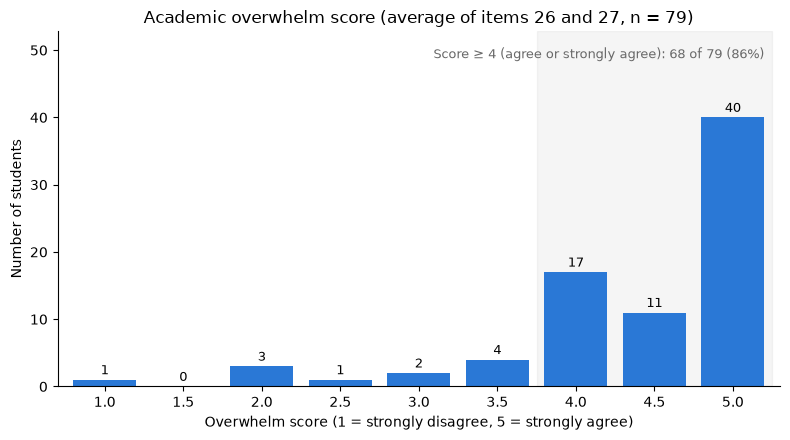

In [51]:
OVERWHELM_COLS = ["26", "27"]  # overwhelmed by academic expectations / by academic workload, each 1-5

# Overwhelm score = average of the two answers (4 students skipped item 27, so their score is item 26 alone)
df["overwhelm"] = df[OVERWHELM_COLS].mean(axis=1)

scores = df["overwhelm"].dropna()
n = len(scores)
high = (scores >= 4).sum()
rho = df["26"].corr(df["27"], method="spearman")
print(f"Overwhelm score: n = {n}, average = {scores.mean():.2f}, score ≥ 4: {high} ({high / n:.0%})")
print(f"Correlation between item 26 and item 27: Spearman ρ = {rho:.2f}")

# Number of students at every possible score, including scores nobody got
levels = [1 + 0.5 * i for i in range(9)]
counts = scores.value_counts().reindex(levels, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axvspan(3.75, 5.25, color="grey", alpha=0.08)
ax.text(5.2, counts.max() * 1.22, f"Score ≥ 4 (agree or strongly agree): {high} of {n} ({high / n:.0%})",
        fontsize=9, color="dimgrey", ha="right")
bars = ax.bar(counts.index, counts.values, width=0.4, color=ND_COLOR)
for bar, c in zip(bars, counts.values):
    ax.annotate(str(c), (bar.get_x() + bar.get_width() / 2, c),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)

ax.set_title(f"Academic overwhelm score (average of items 26 and 27, n = {n})")
ax.set_xlabel("Overwhelm score (1 = strongly disagree, 5 = strongly agree)")
ax.set_ylabel("Number of students")
ax.set_xticks(levels)
ax.set_xlim(0.7, 5.3)
ax.set_ylim(0, counts.max() * 1.32)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Average answers by overwhelm group

This chart compares the **high overwhelm** group (score ≥ 4, 68 students) with the **low/moderate overwhelm** group (score < 4, 11 students). It shows the **average answer** of each group on four questions answered from 1 to 5:
- **Feeling anxious (63)**, **Feeling depressed (64)**, **Stress level (48)**: a higher number means more often or more intense.
- **Mental state since starting uni (51)**: 1 = greatly worsened, 3 = no change, 5 = greatly improved. A **lower** number means the student's mental state has **got worse** since starting vet school.

**Statistical test: Mann-Whitney U test.** It checks whether one group tends to give higher answers than the other. It is used instead of a t-test because the answers are on a 1–5 scale, not exact measurements. A **p-value below 0.05** means the difference is *statistically significant* (probably real, not chance).

**Results**
- Highly overwhelmed students **feel anxious more often** (4.2 vs 3.5, p = 0.003) and have **higher stress** (4.3 vs 3.7, p = 0.011). Both differences are significant.
- Highly overwhelmed students say their **mental state has got worse since starting university** more than the others (2.0 vs 2.8, p = 0.014). An average of 2.0 means *worsened*, while 2.8 is close to *no change*. This is significant and is the most direct sign in the survey that vet school is linked to worse mental health.
- They also **feel depressed more often** (3.3 vs 2.6), but this difference is not significant (p = 0.084).

High overwhelm: 68 students, low/moderate overwhelm: 11 students


,question,low/moderate overwhelm average,high overwhelm average,p-value
0,Feeling anxious (63),3.455,4.206,0.003
1,Feeling depressed (64),2.636,3.265,0.084
2,Stress level (48),3.727,4.324,0.011
3,"Mental state since uni (51) 1 = greatly worse,...",2.818,2.015,0.014


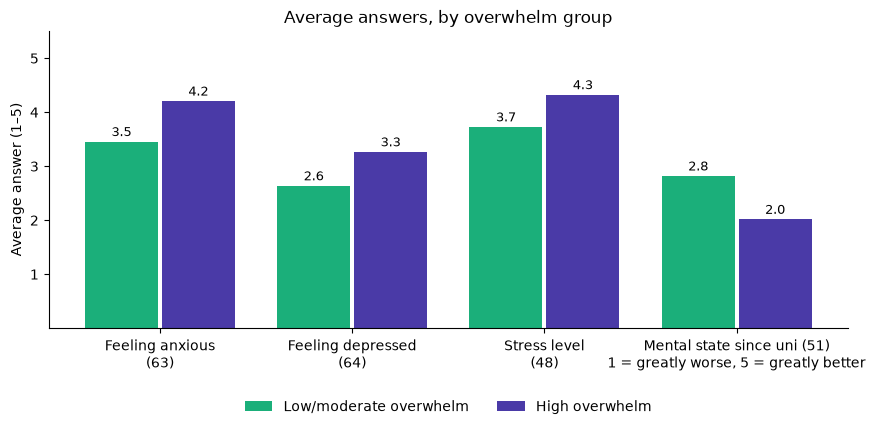

In [52]:
from scipy import stats

HIGH_COLOR = "#4a3aa7"
LOW_COLOR = "#1baf7a"

# High overwhelm = overwhelm score of 4 or more (agrees, on average, that they feel overwhelmed)
df["high_overwhelm"] = df["overwhelm"] >= 4
print(f"High overwhelm: {df['high_overwhelm'].sum()} students, "
      f"low/moderate overwhelm: {(~df['high_overwhelm']).sum()} students")

QUESTIONS = [
    ("Feeling anxious\n(63)", "63"),
    ("Feeling depressed\n(64)", "64"),
    ("Stress level\n(48)", "48"),
    ("Mental state since uni (51)\n1 = greatly worse, 5 = greatly better", "51"),
]

rows = []
for name, col in QUESTIONS:
    low = df.loc[~df["high_overwhelm"], col].dropna()
    high = df.loc[df["high_overwhelm"], col].dropna()
    # Mann-Whitney U test: do the high-overwhelm students tend to give higher answers?
    rows.append({
        "question": name.replace("\n", " "),
        "low/moderate overwhelm average": low.mean(),
        "high overwhelm average": high.mean(),
        "p-value": stats.mannwhitneyu(high, low).pvalue,
    })
averages = pd.DataFrame(rows)
display(averages.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = range(len(QUESTIONS))
for offset, col, color, label in [(-0.2, "low/moderate overwhelm average", LOW_COLOR, "Low/moderate overwhelm"),
                                  (0.2, "high overwhelm average", HIGH_COLOR, "High overwhelm")]:
    bars = ax.bar([i + offset for i in x], averages[col], width=0.38, color=color, label=label)
    for bar, value in zip(bars, averages[col]):
        ax.annotate(f"{value:.1f}", (bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)

ax.set_xticks(list(x), [name for name, _ in QUESTIONS])
ax.set_ylabel("Average answer (1–5)")
ax.set_ylim(0, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_title("Average answers, by overwhelm group")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

  ### How strongly each outcome is linked to feeling overwhelmed

The previous chart split students into two groups, and the low group has only 11 students. This chart uses the **full overwhelm score (1–5)** for every student instead, so no information is lost and the small group size no longer matters.

**Statistical test: Spearman correlation (ρ).** It measures whether one thing tends to go up when another goes up. It goes from −1 to +1:
- **Positive bar**: the more overwhelmed the student, the higher the outcome.
- **Negative bar**: the more overwhelmed the student, the lower the outcome.
- **Size**: around 0.1 is weak, 0.3 is moderate and 0.5 is strong.

**Results**
- **Every outcome is significantly linked to feeling overwhelmed** (all p < 0.05).
- The more overwhelmed students feel, the higher their anxiety (ρ = 0.26), depression (ρ = 0.38), feelings of anxiety (ρ = 0.44) and depression (ρ = 0.42), and stress (ρ = 0.45). These are moderate relationships.
- The bar for mental state since starting uni is negative (ρ = −0.43): the more overwhelmed the student, the more their mental state has **worsened** since starting university.

**Conclusion and limits**

Students who feel more overwhelmed by the workload and expectations of vet school also report more anxiety, depression and stress, and feel their mental health has got worse since starting university. This survey was answered only once, so it shows a **link, not proof of cause**: it is also possible that students who were already anxious feel the same workload as more overwhelming.

,outcome,Spearman ρ,p-value
0,Anxiety (GAD-7),0.256,0.023
1,Depression (PHQ-9),0.376,0.001
2,Feeling anxious (63),0.443,0.000
3,Feeling depressed (64),0.425,0.000
4,Stress level (48),0.448,0.000
5,Mental state since starting uni (51),-0.433,0.000


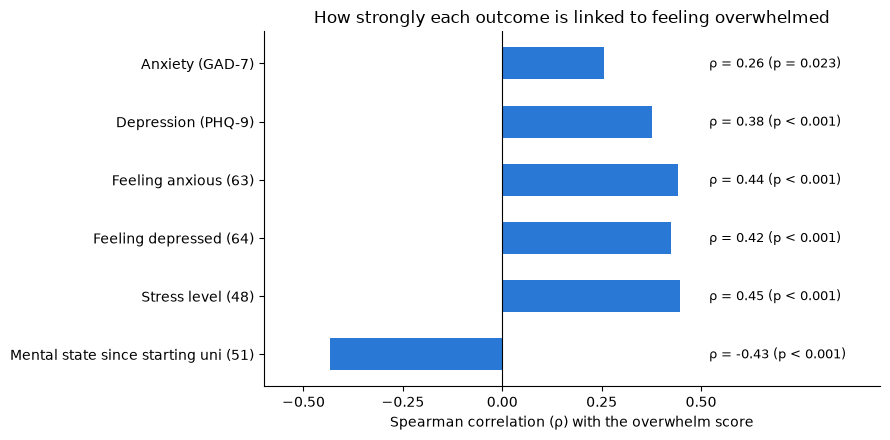

In [53]:
# Spearman correlation: does each outcome go up (or down) as the overwhelm score goes up?
ALL_OUTCOMES = [
    ("Anxiety (GAD-7)", "gad7_total"),
    ("Depression (PHQ-9)", "phq9_total"),
    ("Feeling anxious (63)", "63"),
    ("Feeling depressed (64)", "64"),
    ("Stress level (48)", "48"),
    ("Mental state since starting uni (51)", "51"),
]

rows = []
for name, col in ALL_OUTCOMES:
    rho, p = stats.spearmanr(df["overwhelm"], df[col], nan_policy="omit")
    rows.append({"outcome": name, "Spearman ρ": rho, "p-value": p})
correlations = pd.DataFrame(rows)
display(correlations.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
y = range(len(ALL_OUTCOMES))
ax.barh(list(y), correlations["Spearman ρ"], height=0.55, color=ND_COLOR)
for i, (rho, p) in enumerate(zip(correlations["Spearman ρ"], correlations["p-value"])):
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    ax.text(0.52, i, f"ρ = {rho:.2f} ({p_text})", va="center", fontsize=9)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(list(y), correlations["outcome"])
ax.invert_yaxis()
ax.set_xlim(-0.6, 0.95)
ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
ax.set_xlabel("Spearman correlation (ρ) with the overwhelm score")
ax.set_title("How strongly each outcome is linked to feeling overwhelmed")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Distress and wellbeing by year of study

### Depression and anxiety scores by year of study

**What the graph shows**
- Left: **depression** score (PHQ-9, from 0 to 27). Right: **anxiety** score (GAD-7, from 0 to 21). A higher score means more symptoms.
- Students are split into 4 groups: **early years** (1–2), **middle years** (3–4), **final year** (5+) and **graduates** (in grey). Years are combined because years 3 and 4 alone have only 8 and 6 students, too few to compare.
- Each **bar** is the **average score** of the group. Each **grey dot** is one student.
- The **shaded area** marks a score of 10 or more, which means at least *moderate* symptoms.
- Under each bar: the number of students (n), the average score and the **% of students who score 10 or more**.

**Method: Mann-Whitney U test**

This test compares two groups and tells us whether one group tends to have higher scores than the other, or whether the difference could just be chance. It gives a **p-value**: if it is **below 0.05**, the difference is *statistically significant*, meaning it is very unlikely to be due to chance.

Three comparisons are made:
1. Middle-year students vs all other students.
2. Final-year students vs all other students.
3. Graduates vs all current students.

**Conclusions**
- **Middle-year and final-year students have similar scores to the other students.** Depression: middle 15.4 vs 15.4, final 13.7 vs 15.8. Anxiety: middle 11.7 vs 13.0, final 13.4 vs 12.5. None of these differences is significant.
- **Depression and anxiety are high in every year of study**: 67–84% of students have at least moderate depression and 57–88% at least moderate anxiety.
- **Graduates have significantly less depression** than current students (average 10.3 vs 15.4, p = 0.010). They also have less anxiety (8.9 vs 12.7), but this difference is not significant (p = 0.088).

,students
year_group,
Early years\n(1–2),38
Middle years\n(3–4),14
Final year\n(5+),17
Graduates\n,10


,score,comparison,group average,others average,p-value
0,Depression (PHQ-9),Middle years vs other students,15.357,15.358,0.938
1,Depression (PHQ-9),Final year vs other students,13.733,15.827,0.225
2,Depression (PHQ-9),Graduates vs all students,10.300,15.358,0.010
3,Anxiety (GAD-7),Middle years vs other students,11.714,13.000,0.346
4,Anxiety (GAD-7),Final year vs other students,13.353,12.538,0.525
5,Anxiety (GAD-7),Graduates vs all students,8.900,12.739,0.088


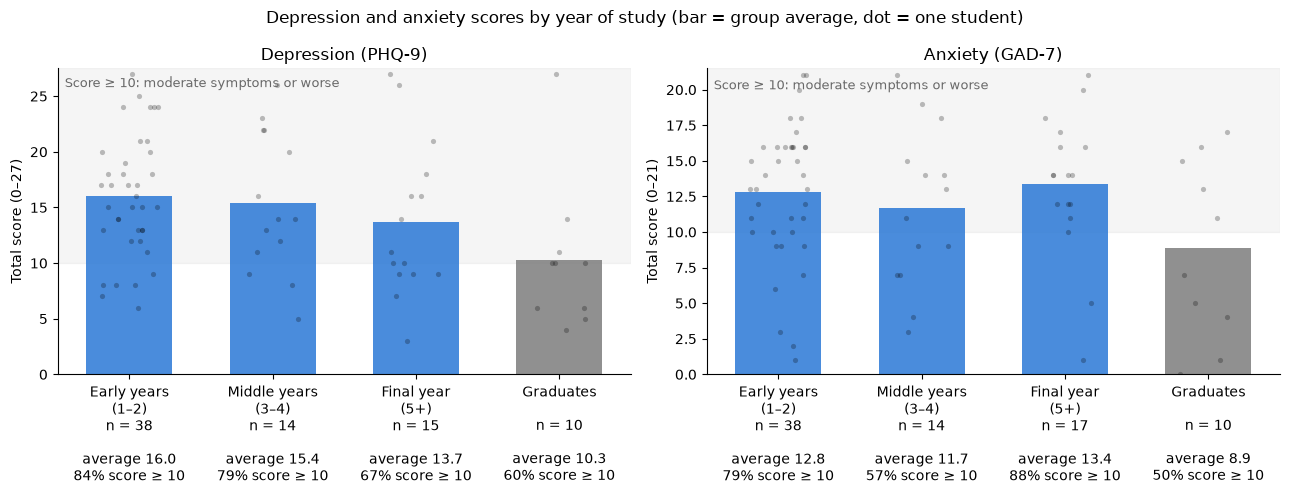

In [69]:
import numpy as np

# Years are combined into 4 groups so that no group is too small to compare (years 3 and 4 alone have only 8 and 6 students)
YEAR_GROUPS = {"1": "Early years\n(1–2)", "2": "Early years\n(1–2)", "3": "Middle years\n(3–4)", "4": "Middle years\n(3–4)",
               "5+": "Final year\n(5+)", "Graduated": "Graduates\n"}
GROUP_ORDER = ["Early years\n(1–2)", "Middle years\n(3–4)", "Final year\n(5+)", "Graduates\n"]
GROUP_COLORS = [ND_COLOR, ND_COLOR, ND_COLOR, "#7d7d7d"]  # graduates in grey: they are no longer studying

df["year_group"] = df["8"].map(YEAR_GROUPS)
# Year as a number (1-5) for the trend test; graduates are left out because they are not a "year 6"
df["year_num"] = df["8"].map({"1": 1, "2": 2, "3": 3, "4": 4, "5+": 5})
students = df[df["8"] != "Graduated"]
graduates = df[df["8"] == "Graduated"]
display(df["year_group"].value_counts().reindex(GROUP_ORDER).to_frame("students"))

DISTRESS = [("Depression (PHQ-9)", "phq9_total", 27), ("Anxiety (GAD-7)", "gad7_total", 21)]

# Mann-Whitney U tests, one for each part of the theory
rows = []
for name, col, _ in DISTRESS:
    for question, group, others in [
        ("Middle years vs other students", students[students["8"].isin(["3", "4"])], students[~students["8"].isin(["3", "4"])]),
        ("Final year vs other students", students[students["8"] == "5+"], students[students["8"] != "5+"]),
        ("Graduates vs all students", graduates, students),
    ]:
        rows.append({"score": name, "comparison": question,
                     "group average": group[col].mean(), "others average": others[col].mean(),
                     "p-value": stats.mannwhitneyu(group[col].dropna(), others[col].dropna()).pvalue})
display(pd.DataFrame(rows).round(3))

rng = np.random.default_rng(0)  # fixed jitter so the dots land in the same place on every run
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, col, max_score) in zip(axes, DISTRESS):
    ax.axhspan(10, max_score + 0.5, color="grey", alpha=0.08)
    ax.text(-0.45, max_score - 0.2, "Score ≥ 10: moderate symptoms or worse", fontsize=9, color="dimgrey", va="top")
    tick_labels = []
    for i, (group, color) in enumerate(zip(GROUP_ORDER, GROUP_COLORS)):
        scores = df.loc[df["year_group"] == group, col].dropna()
        tick_labels.append(f"{group}\nn = {len(scores)}\n\naverage {scores.mean():.1f}\n{(scores >= 10).mean():.0%} score ≥ 10")
        # Bar = group average, faint dots = individual students
        ax.bar(i, scores.mean(), width=0.6, color=color, alpha=0.85)
        ax.scatter(i + rng.uniform(-0.2, 0.2, len(scores)), scores, s=14, color="black", alpha=0.25, linewidths=0)
    ax.set_xticks(range(len(GROUP_ORDER)), tick_labels)
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, max_score + 0.5)
    ax.set_ylabel(f"Total score (0–{max_score})")
    ax.set_title(name)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Depression and anxiety scores by year of study (bar = group average, dot = one student)")
plt.tight_layout()
plt.show()

### Daily wellbeing and lifestyle by year of study

**What the graph shows**
- Each row is one lifestyle statement (columns 41–47), answered from 1 (strongly disagree) to 5 (strongly agree).
- Each box is the **% of students in that group who agree** (answered 4 or 5). Darker blue = more students agree.
- The last row, **stress (48)**, shows the % of students with **high or very high stress**. It is set apart because here a *higher* % means *worse* wellbeing.
- Example: 76% of final-year students agree that they eat regular meals, compared with 39% in the early years.

**Method: Spearman correlation (ρ)**

This checks whether answers go **up or down as the year of study goes up** (year 1, 2, 3, 4, 5; graduates are left out because they are not a "year 6"). The result is written to the right of each row:
- ρ goes from −1 to +1. **Positive** = students in higher years agree **more**. **Negative** = students in higher years agree **less**. Close to 0 = no change.
- Around 0.1 is a weak link, 0.3 moderate and 0.5 strong.
- The **p-value** says whether the trend is real: **below 0.05** = significant (shown in **bold**).

**Conclusions**
- **Lifestyle habits stay about the same across years of study.** No statement gets significantly worse in higher years.
- **Students in higher years eat regular meals more often** (39% in the early years vs 76% in the final year; ρ = +0.26, p = 0.03). This is the only significant change.
- **Stress is high in every year**: 80–88% of students report high or very high stress, with no change across years.
- **Sleep, exercise and free time are low in every group**: in most groups fewer than half of students sleep 7–9 hours or exercise regularly, and only 14–29% feel they have time for errands.

,Early years (1–2),Middle years (3–4),Final year (5+),Graduates
Eat regular meals (41),39.0,29.0,76.0,50.0
Sleep 7–9 hours (42),26.0,50.0,47.0,40.0
Socialize regularly (43),34.0,36.0,47.0,50.0
Exercise 2–3 times a week (44),42.0,29.0,35.0,40.0
Time for errands (45),29.0,14.0,29.0,20.0
Contact with people back home (46),50.0,36.0,35.0,40.0
Speak with family often (47),79.0,57.0,76.0,70.0
High stress (48) – higher % is worse,82.0,86.0,88.0,80.0


,Spearman ρ with year,p-value
Eat regular meals (41),0.255,0.034
Sleep 7–9 hours (42),0.186,0.127
Socialize regularly (43),0.094,0.443
Exercise 2–3 times a week (44),0.041,0.740
Time for errands (45),0.047,0.699
Contact with people back home (46),-0.098,0.422
Speak with family often (47),-0.045,0.716
High stress (48) – higher % is worse,-0.087,0.478


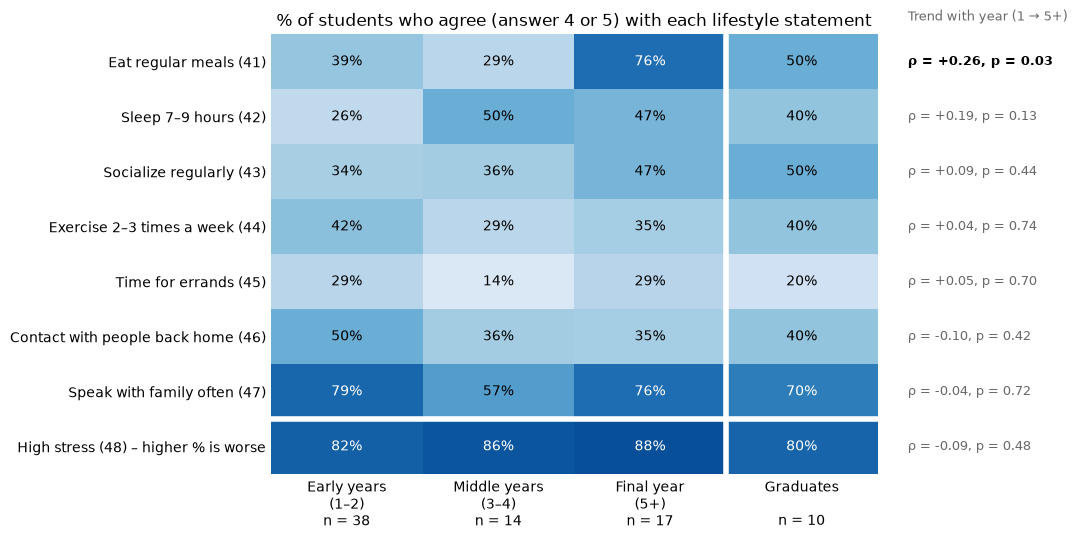

In [70]:
LIFESTYLE = [
    ("41", "Eat regular meals (41)"),
    ("42", "Sleep 7–9 hours (42)"),
    ("43", "Socialize regularly (43)"),
    ("44", "Exercise 2–3 times a week (44)"),
    ("45", "Time for errands (45)"),
    ("46", "Contact with people back home (46)"),
    ("47", "Speak with family often (47)"),
    ("48", "Stress level (48)"),
]
LIFESTYLE_COLS = [col for col, _ in LIFESTYLE]
LIFESTYLE_LABELS = [label for _, label in LIFESTYLE]
# In this chart the stress row counts students with HIGH stress, so a higher % means worse wellbeing
AGREE_LABELS = LIFESTYLE_LABELS[:-1] + ["High stress (48) – higher % is worse"]

# % of each group answering 4 or 5 (agree / strongly agree; for stress: high / very high)
agree = (df[LIFESTYLE_COLS] >= 4).where(df[LIFESTYLE_COLS].notna()).groupby(df["year_group"]).mean().T
agree = agree.reindex(columns=GROUP_ORDER).set_axis(AGREE_LABELS)

# Spearman correlation between year (1-5) and the answer: do answers go up or down in higher years?
trend = pd.DataFrame(
    [stats.spearmanr(students["year_num"], students[col], nan_policy="omit") for col in LIFESTYLE_COLS],
    index=AGREE_LABELS, columns=["Spearman ρ with year", "p-value"])
display((agree * 100).round(0).set_axis([g.replace("\n", " ") for g in GROUP_ORDER], axis=1))
display(trend.round(3))

fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(agree.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for r in range(agree.shape[0]):
    for c in range(agree.shape[1]):
        value = agree.iat[r, c]
        ax.text(c, r, f"{value:.0%}", ha="center", va="center", fontsize=10, color="white" if value > 0.6 else "black")
    rho, p = trend.iloc[r]
    ax.text(3.7, r, f"ρ = {rho:+.2f}, p = {p:.2f}", va="center", fontsize=9,
            color="black" if p < 0.05 else "dimgrey", fontweight="bold" if p < 0.05 else "normal")
ax.text(3.7, -0.75, "Trend with year (1 → 5+)", fontsize=9, color="dimgrey")
ax.axhline(6.5, color="white", linewidth=4)  # stress is set apart: for it, a high % means worse wellbeing
ax.axvline(2.5, color="white", linewidth=4)
ns = df["year_group"].value_counts().reindex(GROUP_ORDER)
ax.set_xticks(range(len(GROUP_ORDER)), [f"{g}\nn = {n}" for g, n in zip(GROUP_ORDER, ns)])
ax.set_yticks(range(len(LIFESTYLE)), AGREE_LABELS)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("% of students who agree (answer 4 or 5) with each lifestyle statement")
plt.tight_layout()
plt.show()

## How students see neurodivergence, by condition

### Coding the answers

This section looks at the question *"To you, neurodivergence is primarily…"* (column 14) and compares the answers of students who ticked each condition in column 10 (*"Which of the following apply to you?"*).

**How the answers were coded**
- Column 14 had 4 fixed options plus an *Other* box. **8 students wrote their own answer.** Each one was read: all of them combine several options (e.g. *"all of the above"*, *"a brain difference that also causes challenges"*, *"it depends on the neurodivergence"*). They are grouped as **Mixed / several views** instead of being forced into one option.
- The 5 answers are put in order, from a **deficit / medical view** (left, red) to a **difference / strengths view** (right, blue), with *Mixed* in grey in the middle.

**How the conditions were grouped**
- Column 10 allowed more than one answer, so **a student who ticked 3 conditions is counted in all 3 rows.** The rows are not separate groups of people and do not add up to 79.
- Conditions ticked by fewer than 5 students (bipolar, SPD, APD, BPD, dyspraxia) are pooled as **Other conditions**.
- *Not sure* and *No condition ticked* (column 10 left empty) are kept as comparison rows.

In [ ]:
# Column 14 has 4 fixed options plus free-text "Other" answers. Every free-text answer was read and coded by hand:
# all of them combine several of the fixed options ("all of the above", "a difference AND a challenge", "it depends"),
# so they get their own category instead of being forced into one option.
VIEW_ORDER = [
    "A disorder needing treatment",
    "A challenge in daily life",
    "Mixed / several views",
    "A brain difference, not a deficit",
    "A unique way of thinking",
]
# Ordered from a deficit / medical view (left) to a difference / strengths view (right)
VIEW_COLORS = ["#b8302f", "#f0a09f", "#c3c2b7", "#86b6ef", "#1c5cab"]

df["view"] = df["14"].where(df["14"].isin(VIEW_ORDER) | df["14"].isna(), "Mixed / several views")
display(df.loc[df["view"] == "Mixed / several views", "14"].to_frame("free-text answers coded as 'Mixed / several views'"))
display(df["view"].value_counts().reindex(VIEW_ORDER).to_frame("students"))

# Column 10 is multi-select: one True/False column per condition. A student who ticked 3 conditions appears in 3 rows.
cond = df["10"].str.get_dummies(sep=";").astype(bool)
cond.columns = cond.columns.str.split(" – ").str[0]
# Conditions with fewer than 5 students are pooled so that no row rests on 1–3 people
SMALL = ["Bipolar Disorder", "Sensory Processing Differences (SPD)", "APD", "BPD", "Dyspraxia / DCD"]
cond["Other conditions"] = cond[SMALL].any(axis=1)
cond["No condition ticked"] = df["10"].isna()  # left column 10 empty
cond = cond.drop(columns=SMALL + ["None"])  # "None" was only ticked together with "Not sure"

COND_ORDER = ["ADHD", "Anxiety Disorder", "Depression Disorder", "ASD", "Dyslexia", "PTSD", "OCD",
              "Other conditions", "Not sure", "No condition ticked"]
# One categorical color per condition, in fixed order; "Not sure" and "No condition ticked" stay grey
COND_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948",
               "#898781", "#c3c2b7"]

# Long table: one row per (student, condition they ticked)
long = (cond[COND_ORDER].join(df["view"]).dropna(subset=["view"])
        .melt(id_vars="view", var_name="condition", value_name="ticked")
        .query("ticked").drop(columns="ticked"))
counts = pd.crosstab(long["condition"], long["view"]).reindex(index=COND_ORDER, columns=VIEW_ORDER, fill_value=0)
share = counts.div(counts.sum(axis=1), axis=0)
display(counts.assign(total=counts.sum(axis=1)))

### Answers by condition (100% stacked bars)

**What the graph shows**
- Each bar is the students who ticked one condition, and adds up to 100%. The colored parts show how those students answered column 14.
- Red = deficit view, grey = mixed, blue = difference view.
- **n** is the number of students in the row. Rows with n below 10 (dyslexia, PTSD, OCD, other) should be read with care: one student changes the bar by 10–20%.

**Conclusions**
- **No student who ticked a condition sees neurodivergence as "a disorder needing treatment".** The only 2 students who chose it ticked no condition at all.
- **For ADHD, anxiety and depression, answers are split**: 35–41% see it as *a challenge in daily life* and 39–49% as *a brain difference* or *a unique way of thinking*.
- **Students with dyslexia are the most positive**: 8 of 9 see it as a difference or a unique way of thinking.
- **Students with ASD give the most mixed answers** (31% wrote their own mixed answer) and none chose *a unique way of thinking*.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
left = np.zeros(len(COND_ORDER))
for view, color in zip(VIEW_ORDER, VIEW_COLORS):
    widths = share[view].values
    ax.barh(range(len(COND_ORDER)), widths, left=left, height=0.7, color=color,
            edgecolor="white", linewidth=1.5, label=view)
    for i, (w, n) in enumerate(zip(widths, counts[view].values)):
        if w >= 0.08:  # label only segments wide enough to hold the text
            ax.text(left[i] + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if color in ("#b8302f", "#1c5cab") else "black")
    left += widths

totals = counts.sum(axis=1)
ax.set_yticks(range(len(COND_ORDER)), [f"{c}  (n = {n})" for c, n in zip(COND_ORDER, totals)])
ax.invert_yaxis()
ax.axhline(7.5, color="black", linewidth=0.6, linestyle=":")  # conditions above, "unsure / none" below
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("% of students who ticked this condition")
ax.set_title("“To you, neurodivergence is primarily…” (column 14), by condition (column 10)", loc="left")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.1), frameon=False, fontsize=9)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### One dot per student

**What the graph shows**
- The same data as the bars above, but **each dot is one student** and each condition has its own color. This shows how *few* students sit behind some of the percentages, e.g. PTSD and OCD have only 5 dots each.
- A student who ticked several conditions appears as a dot in several rows.

In [ ]:
rng = np.random.default_rng(0)  # fixed jitter so the dots land in the same place on every run
fig, ax = plt.subplots(figsize=(12, 6.5))
for i, (condition, color) in enumerate(zip(COND_ORDER, COND_COLORS)):
    for j, view in enumerate(VIEW_ORDER):
        n = counts.at[condition, view]
        # Dots are packed in a small grid inside each cell, so every dot is one student and none overlap
        cols = 6
        xs = j + (np.arange(n) % cols - (cols - 1) / 2) * 0.1
        ys = i + (np.arange(n) // cols - (np.ceil(n / cols) - 1) / 2) * 0.17
        ax.scatter(xs, ys, s=38, color=color, edgecolor="white", linewidth=0.8, zorder=3)
for j in range(len(VIEW_ORDER) - 1):
    ax.axvline(j + 0.5, color="#e1e0d9", linewidth=0.8)
for i in range(len(COND_ORDER) - 1):
    ax.axhline(i + 0.5, color="#e1e0d9", linewidth=0.8)
ax.set_xticks(range(len(VIEW_ORDER)), [v.replace(", ", ",\n").replace(" in ", "\nin ").replace(" needing", "\nneeding")
                                       .replace(" of ", "\nof ").replace(" / ", " /\n") for v in VIEW_ORDER])
ax.set_yticks(range(len(COND_ORDER)), [f"{c}  (n = {n})" for c, n in zip(COND_ORDER, totals)])
ax.set_xlim(-0.5, len(VIEW_ORDER) - 0.5)
ax.set_ylim(len(COND_ORDER) - 0.5, -0.5)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("One dot = one student who ticked that condition (students with several conditions appear in several rows)",
             loc="left", fontsize=10, pad=50)
plt.tight_layout()
plt.show()

### Is any condition linked to a deficit view? (Fisher's exact test)

**Method**
- The answers are grouped in two: **deficit view** (*a disorder needing treatment* or *a challenge in daily life*) and **difference view** (*a brain difference, not a deficit* or *a unique way of thinking*). The 8 *Mixed* answers are left out.
- For each condition, students who ticked it are compared with everyone else.
- **Fisher's exact test** is used instead of a chi-square test because many groups are very small. A **p-value below 0.05** means the difference is unlikely to be due to chance.
- **Odds ratio**: above 1 = students with this condition lean more to the deficit view than everyone else; below 1 = they lean more to the difference view.

**Conclusions**
- **No condition is significantly linked to how students see neurodivergence** (all p > 0.05). With these small groups, only very large differences could be detected.
- **Dyslexia comes closest**: 11% of students with dyslexia have a deficit view vs 44% of everyone else (p = 0.075). This is a trend worth mentioning, not a finding.
- Students with anxiety or depression lean slightly more to the deficit view (50% vs 35–38%), but this is not significant.

In [ ]:
# Deficit view = "disorder needing treatment" or "challenge in daily life"
# Difference view = "brain difference, not a deficit" or "unique way of thinking". "Mixed" answers are left out.
framing = df["view"].map({VIEW_ORDER[0]: "Deficit view", VIEW_ORDER[1]: "Deficit view",
                          VIEW_ORDER[3]: "Difference view", VIEW_ORDER[4]: "Difference view"})
rows = []
for condition in COND_ORDER:
    ticked = cond[condition]
    a = ((framing == "Deficit view") & ticked).sum()
    b = ((framing == "Difference view") & ticked).sum()
    c = ((framing == "Deficit view") & ~ticked).sum()
    d = ((framing == "Difference view") & ~ticked).sum()
    odds, p = stats.fisher_exact([[a, b], [c, d]])
    rows.append({"condition": condition, "n (deficit + difference)": a + b,
                 "% deficit view: ticked": a / (a + b), "% deficit view: everyone else": c / (c + d),
                 "odds ratio": odds, "p-value (Fisher)": p})
framing_table = pd.DataFrame(rows).set_index("condition")
pct_cols = ["% deficit view: ticked", "% deficit view: everyone else"]
display(framing_table.assign(**{c: framing_table[c] * 100 for c in pct_cols}).round({**dict.fromkeys(pct_cols, 0), "odds ratio": 2, "p-value (Fisher)": 3}))